<a href="https://colab.research.google.com/github/Mhamuda/CSEM2151-Computer_Vision/blob/main/Assignment15_Mamba.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Mount Google Drive

In [ ]:

from google.colab import drive

drive.mount("/content/drive")


Mounted at /content/drive


#Create Project Directories

In [ ]:

from pathlib import Path
import os
import random
import json
import time
import shutil
import zipfile
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, UnidentifiedImageError
from collections import Counter

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba"
)

DATA_DIR = PROJECT_DIR / "data"
DOWNLOAD_DIR = DATA_DIR / "downloads"
EXTRACT_DIR = DATA_DIR / "downloaded"
OUTPUT_DIR = PROJECT_DIR / "outputs"
MODEL_DIR = OUTPUT_DIR / "models"
RESULTS_DIR = OUTPUT_DIR / "results"
FIGURES_DIR = OUTPUT_DIR / "figures"
REPORT_DIR = OUTPUT_DIR / "report"

for folder in [
    DOWNLOAD_DIR,
    EXTRACT_DIR,
    MODEL_DIR,
    RESULTS_DIR,
    FIGURES_DIR,
    REPORT_DIR,
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Dataset download directory:", DOWNLOAD_DIR)
print("Extracted dataset directory:", EXTRACT_DIR)
print("Model directory:", MODEL_DIR)
print("Results directory:", RESULTS_DIR)
print("Figures directory:", FIGURES_DIR)
print("Report directory:", REPORT_DIR)


Project directory: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba
Dataset download directory: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba/data/downloads
Extracted dataset directory: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba/data/downloaded
Model directory: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba/outputs/models
Results directory: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba/outputs/results
Figures directory: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba/outputs/figures
Report directory: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba/outputs/report


#Download and Extract the Dataset Automatically

In [ ]:

from pathlib import Path
import subprocess

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba"
)
DATA_DIR = PROJECT_DIR / "data"
REPO_DIR = DATA_DIR / "IndiUrbanClean-Dataset"

DATA_DIR.mkdir(parents=True, exist_ok=True)

if (REPO_DIR / ".git").exists():
    print("Repository already exists. Updating it...")
    subprocess.run(
        ["git", "-C", str(REPO_DIR), "pull"],
        check=True
    )
else:
    print("Cloning the public dataset repository...")
    subprocess.run(
        [
            "git", "clone", "--depth", "1",
            "https://github.com/Mahek-S/IndiUrbanClean-Dataset.git",
            str(REPO_DIR)
        ],
        check=True
    )

print("\nDownload completed.")
print("Dataset location:", REPO_DIR)

print("\nFiles and folders:")
subprocess.run(
    ["find", str(REPO_DIR), "-maxdepth", "3", "-type", "d"],
    check=True
)


Cloning the public dataset repository...

Download completed.
Dataset location: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba/data/IndiUrbanClean-Dataset

Files and folders:


CompletedProcess(args=['find', '/content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba/data/IndiUrbanClean-Dataset', '-maxdepth', '3', '-type', 'd'], returncode=0)

In [ ]:

from pathlib import Path
from collections import Counter

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba"
)

REPO_DIR = (
    PROJECT_DIR / "data" / "IndiUrbanClean-Dataset"
)

print("Repository exists:", REPO_DIR.exists())
print("Repository path:", REPO_DIR)
print("\nTop-level contents:")

for item in sorted(REPO_DIR.iterdir()):
    label = "DIR " if item.is_dir() else "FILE"
    print(f"{label}  {item.name}")

all_files = [
    path for path in REPO_DIR.rglob("*")
    if path.is_file()
    and ".git" not in path.parts
]

print("\nTotal files:", len(all_files))

image_extensions = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

image_files = [
    path for path in all_files
    if path.suffix.lower() in image_extensions
]

print("Total image files:", len(image_files))
print("\nImage extensions:", Counter(
    path.suffix.lower() for path in image_files
))

print("\nSample image paths:")
for path in image_files[:15]:
    print(path.relative_to(REPO_DIR))

print("\nREADME files:")
readme_files = [
    path for path in all_files
    if path.name.lower().startswith("readme")
]

for readme in readme_files[:3]:
    print(f"\n--- {readme.name} ---")
    try:
        print(readme.read_text(encoding="utf-8", errors="replace")[:5000])
    except OSError as error:
        print("Could not read README:", error)

if not image_files:
    print(
        "\nWARNING: No images found. We must inspect the repository "
        "contents before preparing the dataset."
    )


Repository exists: True
Repository path: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba/data/IndiUrbanClean-Dataset

Top-level contents:
DIR   .git
FILE  LICENSE
FILE  README.md
FILE  TransferLearning_Part3.ipynb
DIR   annotations
FILE  coatnet_hybrid_dlcv.ipynb
DIR   docs
DIR   images
DIR   metadata
DIR   project1_augumentation
DIR   splits

Total files: 2035
Total image files: 1981

Image extensions: Counter({'.jpg': 1981})

Sample image paths:
images/clean_street/clean_street_001.jpg
images/clean_street/clean_street_002.jpg
images/clean_street/clean_street_003.jpg
images/clean_street/clean_street_004.jpg
images/clean_street/clean_street_005.jpg
images/clean_street/clean_street_006.jpg
images/clean_street/clean_street_007.jpg
images/clean_street/clean_street_008.jpg
images/clean_street/clean_street_009.jpg
images/clean_street/clean_street_010.jpg
images/clean_street/clean_street_011.jpg
images/clean_street/clean_street_012.jpg
images/clean_street/clean_street_0

#Verify Classes and Image Counts

In [ ]:

from pathlib import Path
import pandas as pd
from PIL import Image
from collections import Counter

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba"
)
REPO_DIR = PROJECT_DIR / "data" / "IndiUrbanClean-Dataset"
IMAGES_DIR = REPO_DIR / "images"
OUTPUT_DIR = PROJECT_DIR / "outputs"
RESULTS_DIR = OUTPUT_DIR / "results"
FIGURES_DIR = OUTPUT_DIR / "figures"

for folder in [RESULTS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

CLASS_MAPPING = {
    "clean_street": "Clean",
    "open_waste": "Dirty",
    "construction_waste": "Dirty",
    "dumpyard": "Dirty",
    "overfilled_bins": "Dirty",
}

rows = []

for source_class, binary_class in CLASS_MAPPING.items():
    class_dir = IMAGES_DIR / source_class

    if not class_dir.exists():
        print("WARNING: Missing folder:", class_dir)
        continue

    images = [
        p for p in class_dir.iterdir()
        if p.is_file() and p.suffix.lower() in {
            ".jpg", ".jpeg", ".png", ".webp", ".bmp"
        }
    ]

    print(f"{source_class}: {len(images)} images -> {binary_class}")

    for path in images:
        rows.append({
            "image_path": str(path),
            "source_class": source_class,
            "label": binary_class,
            "label_id": 0 if binary_class == "Clean" else 1,
        })

dataset_df = pd.DataFrame(rows)

if dataset_df.empty:
    raise ValueError(
        "No images found. Check the repository images folder."
    )

print("\nTotal images found:", len(dataset_df))
print("\nBinary class counts:")
print(dataset_df["label"].value_counts())

summary = (
    dataset_df.groupby(["source_class", "label"])
    .size()
    .reset_index(name="image_count")
)

summary.to_csv(
    RESULTS_DIR / "dataset_class_summary.csv",
    index=False
)

dataset_df.to_csv(
    RESULTS_DIR / "dataset_manifest.csv",
    index=False
)

print("\nSaved dataset summary and image manifest.")
display(summary)


clean_street: 350 images -> Clean
open_waste: 407 images -> Dirty
construction_waste: 416 images -> Dirty
dumpyard: 406 images -> Dirty
overfilled_bins: 402 images -> Dirty

Total images found: 1981

Binary class counts:
label
Dirty    1631
Clean     350
Name: count, dtype: int64

Saved dataset summary and image manifest.


,source_class,label,image_count
0,clean_street,Clean,350
1,construction_waste,Dirty,416
2,dumpyard,Dirty,406
3,open_waste,Dirty,407
4,overfilled_bins,Dirty,402


#Check Image Readability

In [ ]:

from PIL import Image, UnidentifiedImageError

valid_rows = []
invalid_paths = []

for row in dataset_df.to_dict("records"):
    try:
        with Image.open(row["image_path"]) as img:
            img.verify()
        valid_rows.append(row)
    except (OSError, ValueError, UnidentifiedImageError):
        invalid_paths.append(row["image_path"])

dataset_df = pd.DataFrame(valid_rows)

print("Valid images:", len(dataset_df))
print("Unreadable images:", len(invalid_paths))

if invalid_paths:
    pd.DataFrame({
        "image_path": invalid_paths
    }).to_csv(
        RESULTS_DIR / "invalid_images.csv",
        index=False
    )

dataset_df.to_csv(
    RESULTS_DIR / "dataset_manifest.csv",
    index=False
)

display(dataset_df["label"].value_counts().rename("image_count"))


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (101756928 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


Valid images: 1981
Unreadable images: 0


,image_count
label,
Dirty,1631
Clean,350


#Visualize the Dataset Distribution

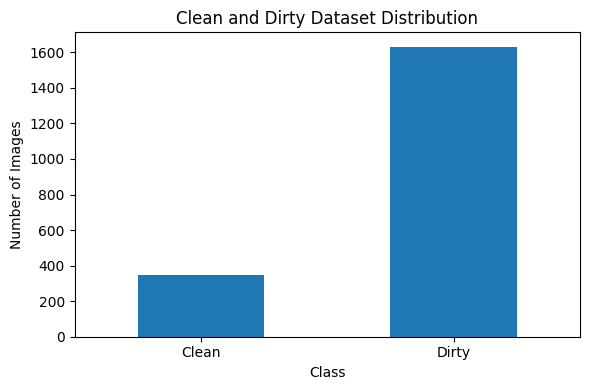

Figure saved to: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba/outputs/figures


In [ ]:

import matplotlib.pyplot as plt

counts = dataset_df["label"].value_counts().reindex(
    ["Clean", "Dirty"], fill_value=0
)

plt.figure(figsize=(6, 4))
counts.plot(kind="bar")
plt.title("Clean and Dirty Dataset Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "dataset_class_distribution.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("Figure saved to:", FIGURES_DIR)


#Create a Balanced Dataset

In [ ]:

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba"
)
REPO_DIR = PROJECT_DIR / "data" / "IndiUrbanClean-Dataset"
IMAGES_DIR = REPO_DIR / "images"

RESULTS_DIR = PROJECT_DIR / "outputs" / "results"
FIGURES_DIR = PROJECT_DIR / "outputs" / "figures"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
SAMPLES_PER_CLASS = 350

CLASS_MAPPING = {
    "clean_street": "Clean",
    "open_waste": "Dirty",
    "construction_waste": "Dirty",
    "dumpyard": "Dirty",
    "overfilled_bins": "Dirty",
}

rows = []

for source_class, binary_class in CLASS_MAPPING.items():
    folder = IMAGES_DIR / source_class

    for path in sorted(folder.iterdir()):
        if path.is_file() and path.suffix.lower() in {
            ".jpg", ".jpeg", ".png", ".bmp", ".webp"
        }:
            rows.append({
                "image_path": str(path),
                "source_class": source_class,
                "label": binary_class,
                "label_id": 0 if binary_class == "Clean" else 1,
            })

all_df = pd.DataFrame(rows)

clean_df = all_df[all_df["label"] == "Clean"]
dirty_df = all_df[all_df["label"] == "Dirty"]

if len(clean_df) < SAMPLES_PER_CLASS:
    raise ValueError("Not enough Clean images.")

if len(dirty_df) < SAMPLES_PER_CLASS:
    raise ValueError("Not enough Dirty images.")

balanced_df = pd.concat([
    clean_df.sample(n=SAMPLES_PER_CLASS, random_state=SEED),
    dirty_df.sample(n=SAMPLES_PER_CLASS, random_state=SEED),
], ignore_index=True)

balanced_df = balanced_df.sample(
    frac=1, random_state=SEED
).reset_index(drop=True)

manifest_path = RESULTS_DIR / "balanced_dataset_manifest.csv"
balanced_df.to_csv(manifest_path, index=False)

print("Balanced dataset created.")
print("Total images:", len(balanced_df))
print("\nClass counts:")
print(balanced_df["label"].value_counts())
print("\nManifest saved to:", manifest_path)

display(
    balanced_df.groupby(["label", "source_class"])
    .size()
    .reset_index(name="image_count")
)


Balanced dataset created.
Total images: 700

Class counts:
label
Clean    350
Dirty    350
Name: count, dtype: int64

Manifest saved to: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba/outputs/results/balanced_dataset_manifest.csv


,label,source_class,image_count
0,Clean,clean_street,350
1,Dirty,construction_waste,94
2,Dirty,dumpyard,87
3,Dirty,open_waste,91
4,Dirty,overfilled_bins,78


#Visualize the Balanced Dataset

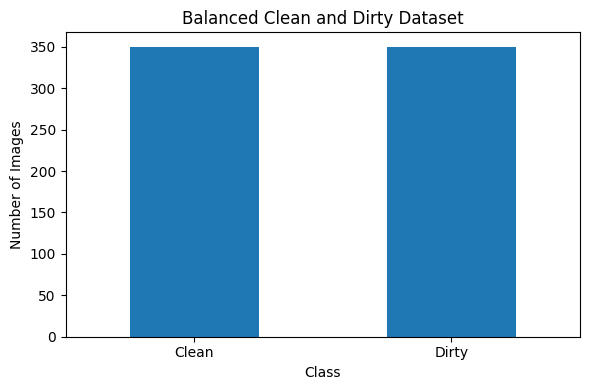

Figure saved to: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba/outputs/figures/balanced_dataset_distribution.png


In [ ]:

import matplotlib.pyplot as plt

class_counts = (
    balanced_df["label"]
    .value_counts()
    .reindex(["Clean", "Dirty"], fill_value=0)
)

plt.figure(figsize=(6, 4))
class_counts.plot(kind="bar")
plt.title("Balanced Clean and Dirty Dataset")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.tight_layout()

figure_path = FIGURES_DIR / "balanced_dataset_distribution.png"
plt.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

print("Figure saved to:", figure_path)


#Visualize Clean and Dirty Dataset Samples

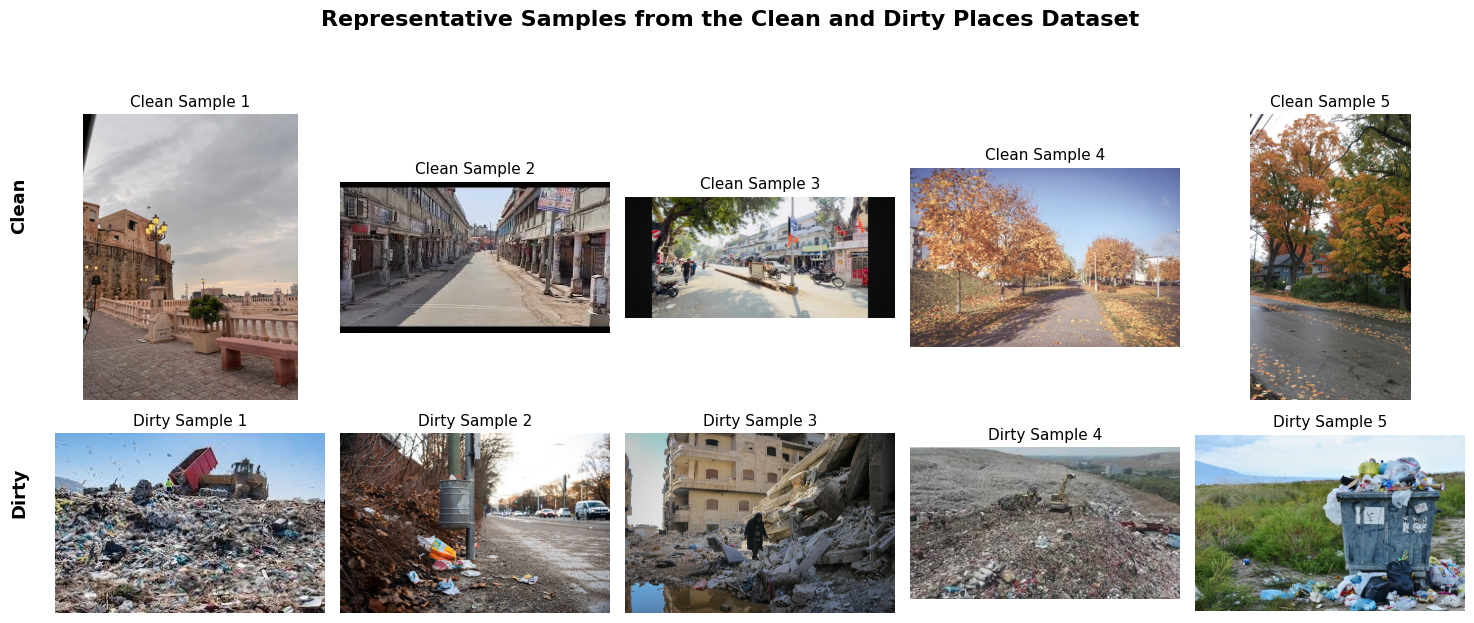

Figure saved successfully!
File path: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba/outputs/figures/clean_dirty_dataset_samples.png


In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# Project directories
PROJECT_DIR = Path(
    "/content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba"
)
FIGURES_DIR = PROJECT_DIR / "outputs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Select 5 images from each class
clean_samples = balanced_df[balanced_df["label"] == "Clean"].sample(
    n=5, random_state=42
)
dirty_samples = balanced_df[balanced_df["label"] == "Dirty"].sample(
    n=5, random_state=42
)

# Create a 2-row x 5-column figure
fig, axes = plt.subplots(2, 5, figsize=(15, 7))

# First row: Clean images
for col, (_, row) in enumerate(clean_samples.iterrows()):
    image = Image.open(row["image_path"]).convert("RGB")
    axes[0, col].imshow(image)
    axes[0, col].set_title(f"Clean Sample {col + 1}", fontsize=11)
    axes[0, col].axis("off")

# Second row: Dirty images
for col, (_, row) in enumerate(dirty_samples.iterrows()):
    image = Image.open(row["image_path"]).convert("RGB")
    axes[1, col].imshow(image)
    axes[1, col].set_title(f"Dirty Sample {col + 1}", fontsize=11)
    axes[1, col].axis("off")

# Overall figure title and row labels
fig.suptitle(
    "Representative Samples from the Clean and Dirty Places Dataset",
    fontsize=16,
    fontweight="bold",
    y=0.98
)

fig.text(0.02, 0.70, "Clean", fontsize=13, fontweight="bold",
         rotation=90, va="center")
fig.text(0.02, 0.29, "Dirty", fontsize=13, fontweight="bold",
         rotation=90, va="center")

plt.tight_layout(rect=[0.04, 0.02, 1, 0.93])

# Save the figure to Google Drive
figure_path = FIGURES_DIR / "clean_dirty_dataset_samples.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

print("Figure saved successfully!")
print("File path:", figure_path)

#Create Training, Validation, and Testing Splits

In [ ]:

from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    balanced_df,
    test_size=0.30,
    random_state=SEED,
    stratify=balanced_df["label_id"],
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label_id"],
)

splits = {
    "train": train_df,
    "val": val_df,
    "test": test_df,
}

for split_name, split_df in splits.items():
    split_path = RESULTS_DIR / f"{split_name}_split.csv"
    split_df.to_csv(split_path, index=False)

    print(f"\n{split_name.upper()}: {len(split_df)} images")
    print(split_df["label"].value_counts().sort_index())

print("\nAll split CSV files saved to:", RESULTS_DIR)

# Verify that no image occurs in more than one split
train_paths = set(train_df["image_path"])
val_paths = set(val_df["image_path"])
test_paths = set(test_df["image_path"])

assert train_paths.isdisjoint(val_paths)
assert train_paths.isdisjoint(test_paths)
assert val_paths.isdisjoint(test_paths)
assert len(train_df) + len(val_df) + len(test_df) == 700

print("\nSplit verification passed: no image-path overlap.")



TRAIN: 490 images
label
Clean    245
Dirty    245
Name: count, dtype: int64

VAL: 105 images
label
Clean    52
Dirty    53
Name: count, dtype: int64

TEST: 105 images
label
Clean    53
Dirty    52
Name: count, dtype: int64

All split CSV files saved to: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba/outputs/results

Split verification passed: no image-path overlap.


#Prepare the Dataset and DataLoaders

In [ ]:
# Install the required libraries
%pip install -q timm scikit-learn pandas matplotlib pillow

#Create PyTorch DataLoaders

In [ ]:
import torch
import pandas as pd
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Project directory
PROJECT_DIR = Path(
    "/content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba"
)
RESULTS_DIR = PROJECT_DIR / "outputs" / "results"

# Device configuration
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# Load the saved dataset splits
train_df = pd.read_csv(RESULTS_DIR / "train_split.csv")
val_df = pd.read_csv(RESULTS_DIR / "val_split.csv")
test_df = pd.read_csv(RESULTS_DIR / "test_split.csv")

# Image transformations
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

# Custom dataset class
class CleanDirtyDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):
        row = self.dataframe.iloc[index]

        image = Image.open(row["image_path"]).convert("RGB")
        label = int(row["label_id"])

        if self.transform:
            image = self.transform(image)

        return image, label

# Create datasets
train_dataset = CleanDirtyDataset(train_df, train_transform)
val_dataset = CleanDirtyDataset(val_df, eval_transform)
test_dataset = CleanDirtyDataset(test_df, eval_transform)

# DataLoaders
BATCH_SIZE = 16
NUM_WORKERS = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda")
)

# Verify the data pipeline
images, labels = next(iter(train_loader))

print("\nDataLoaders created successfully.")
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Label values in this batch:", labels.unique().tolist())
print("Class mapping: 0 = Clean, 1 = Dirty")

Device: cuda
GPU: Tesla T4

DataLoaders created successfully.
Training images: 490
Validation images: 105
Testing images: 105
Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])
Label values in this batch: [0, 1]
Class mapping: 0 = Clean, 1 = Dirty


#Check Pretrained Model Availability

In [ ]:
import torch
import timm
import torchvision

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("timm version:", timm.__version__)

# Check pretrained CNN models
cnn_models = timm.list_models("*resnet18*")
print("\nResNet-18 models:")
print(cnn_models[:10])

# Check pretrained Vision Transformer models
vit_models = timm.list_models("*vit_tiny_patch16_224*")
print("\nVision Transformer models:")
print(vit_models[:10])

# Check pretrained Mamba-family vision models
mamba_models = timm.list_models("*mamba*")
print("\nMamba-family models:")
print(mamba_models[:30])

# Check MambaVision models separately
mambavision_models = timm.list_models("*mambavision*")
print("\nMambaVision models:")
print(mambavision_models[:20])

PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
timm version: 1.0.30

ResNet-18 models:
['legacy_seresnet18', 'resnet18', 'resnet18d', 'seresnet18', 'skresnet18']

Vision Transformer models:
['vit_tiny_patch16_224']

Mamba-family models:
['mambaout_base', 'mambaout_base_plus_rw', 'mambaout_base_short_rw', 'mambaout_base_tall_rw', 'mambaout_base_wide_rw', 'mambaout_femto', 'mambaout_kobe', 'mambaout_small', 'mambaout_small_rw', 'mambaout_tiny', 'test_mambaout']

MambaVision models:
[]


#Load and Verify the Three Pretrained Models

In [ ]:
import torch
import timm
import torch.nn as nn
from pathlib import Path

# Project directory
PROJECT_DIR = Path(
    "/content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba"
)

MODELS_DIR = PROJECT_DIR / "outputs" / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Use pretrained weights and replace the classification head
MODEL_CONFIGS = {
    "ResNet-18": "resnet18",
    "ViT-Tiny": "vit_tiny_patch16_224",
    "MambaOut-Tiny": "mambaout_tiny",
}

models = {}

for model_name, model_id in MODEL_CONFIGS.items():
    print(f"\nLoading {model_name} ({model_id})...")

    try:
        model = timm.create_model(
            model_id,
            pretrained=True,
            num_classes=2
        )

        model = model.to(DEVICE)
        models[model_name] = model

        total_params = sum(p.numel() for p in model.parameters())
        trainable_params = sum(
            p.numel() for p in model.parameters() if p.requires_grad
        )

        print("Model loaded successfully.")
        print(f"Total parameters: {total_params:,}")
        print(f"Trainable parameters: {trainable_params:,}")

    except Exception as error:
        print(f"Could not load {model_name}.")
        print("Error:", repr(error))

print("\n" + "=" * 50)
print("MODEL LOADING SUMMARY")
print("=" * 50)

for model_name in MODEL_CONFIGS:
    print(f"{model_name}: {'Ready' if model_name in models else 'Failed'}")


Loading ResNet-18 (resnet18)...


model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

Model loaded successfully.
Total parameters: 11,177,538
Trainable parameters: 11,177,538

Loading ViT-Tiny (vit_tiny_patch16_224)...


model.safetensors: reconstructing file:   0%|          |  0.00B / 22.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Model loaded successfully.
Total parameters: 5,524,802
Trainable parameters: 5,524,802

Loading MambaOut-Tiny (mambaout_tiny)...


model.safetensors: reconstructing file:   0%|          |  0.00B /  106MB            

model.safetensors: downloading bytes:           |  0.00B            

Model loaded successfully.
Total parameters: 24,244,706
Trainable parameters: 24,244,706

MODEL LOADING SUMMARY
ResNet-18: Ready
ViT-Tiny: Ready
MambaOut-Tiny: Ready


#Test the Models with One Image Batch

In [ ]:
# Verify that each loaded model returns two class scores per image
images, labels = next(iter(train_loader))
images = images.to(DEVICE)

for model_name, model in models.items():
    model.eval()

    with torch.no_grad():
        outputs = model(images)

    print(
        f"{model_name}: "
        f"Input shape = {tuple(images.shape)}, "
        f"Output shape = {tuple(outputs.shape)}"
    )

    assert outputs.shape == (images.shape[0], 2), (
        f"Unexpected output shape for {model_name}"
    )

print("\nAll loaded models passed the output-shape test.")

ResNet-18: Input shape = (16, 3, 224, 224), Output shape = (16, 2)
ViT-Tiny: Input shape = (16, 3, 224, 224), Output shape = (16, 2)
MambaOut-Tiny: Input shape = (16, 3, 224, 224), Output shape = (16, 2)

All loaded models passed the output-shape test.


#Train All Three Models

In [ ]:
import copy
import time
import json
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from pathlib import Path

# Output directories
RESULTS_DIR = PROJECT_DIR / "outputs" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Training configuration
NUM_EPOCHS = 20
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

criterion = nn.CrossEntropyLoss()

training_histories = {}
validation_results = []

for model_name, model in models.items():
    print("\n" + "=" * 65)
    print(f"Training: {model_name}")
    print("=" * 65)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    best_val_f1 = -1.0
    best_state = copy.deepcopy(model.state_dict())
    history = []

    for epoch in range(NUM_EPOCHS):
        epoch_start = time.time()

        # -------------------------
        # Training
        # -------------------------
        model.train()
        train_loss_sum = 0.0
        train_true = []
        train_pred = []

        for images, labels in train_loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)

            train_true.extend(labels.cpu().tolist())
            train_pred.extend(predictions.cpu().tolist())

        train_loss = train_loss_sum / len(train_loader.dataset)
        train_acc = accuracy_score(train_true, train_pred)

        # -------------------------
        # Validation
        # -------------------------
        model.eval()
        val_loss_sum = 0.0
        val_true = []
        val_pred = []

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(DEVICE, non_blocking=True)
                labels = labels.to(DEVICE, non_blocking=True)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss_sum += loss.item() * images.size(0)
                predictions = outputs.argmax(dim=1)

                val_true.extend(labels.cpu().tolist())
                val_pred.extend(predictions.cpu().tolist())

        val_loss = val_loss_sum / len(val_loader.dataset)
        val_acc = accuracy_score(val_true, val_pred)
        val_precision = precision_score(
            val_true, val_pred, zero_division=0
        )
        val_recall = recall_score(
            val_true, val_pred, zero_division=0
        )
        val_f1 = f1_score(
            val_true, val_pred, zero_division=0
        )

        # Save history for this epoch
        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc,
            "val_precision": val_precision,
            "val_recall": val_recall,
            "val_f1": val_f1,
            "epoch_seconds": time.time() - epoch_start,
        })

        # Keep the model with the best validation F1
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_state = copy.deepcopy(model.state_dict())

            checkpoint_path = MODELS_DIR / (
                model_name.lower().replace("-", "_").replace(" ", "_")
                + "_best.pth"
            )

            torch.save({
                "model_name": model_name,
                "model_id": MODEL_CONFIGS[model_name],
                "model_state_dict": best_state,
                "num_classes": 2,
                "class_mapping": {"Clean": 0, "Dirty": 1},
                "best_val_f1": best_val_f1,
                "epoch": epoch + 1,
            }, checkpoint_path)

        print(
            f"Epoch {epoch + 1}/{NUM_EPOCHS} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.4f} | "
            f"Val F1: {val_f1:.4f} | "
            f"Time: {history[-1]['epoch_seconds']:.1f}s"
        )

    # Restore the best validation checkpoint before recording results
    model.load_state_dict(best_state)
    model.eval()

    training_histories[model_name] = history

    history_path = RESULTS_DIR / (
        model_name.lower().replace("-", "_").replace(" ", "_")
        + "_training_history.csv"
    )
    pd.DataFrame(history).to_csv(history_path, index=False)

    best_epoch = max(history, key=lambda item: item["val_f1"])

    validation_results.append({
        "model": model_name,
        "best_epoch": best_epoch["epoch"],
        "val_accuracy": best_epoch["val_accuracy"],
        "val_precision": best_epoch["val_precision"],
        "val_recall": best_epoch["val_recall"],
        "val_f1": best_epoch["val_f1"],
        "checkpoint": str(
            MODELS_DIR / (
                model_name.lower().replace("-", "_").replace(" ", "_")
                + "_best.pth"
            )
        ),
    })

    print(f"Best validation F1: {best_val_f1:.4f}")

# Save a combined validation comparison table
validation_df = pd.DataFrame(validation_results)
validation_path = RESULTS_DIR / "validation_model_comparison.csv"
validation_df.to_csv(validation_path, index=False)

print("\n" + "=" * 65)
print("TRAINING COMPLETED")
print("=" * 65)

display(validation_df)
print("\nValidation results saved to:", validation_path)
print("Model checkpoints saved to:", MODELS_DIR)


Training: ResNet-18
Epoch 1/20 | Train Loss: 0.1939 | Train Acc: 0.9531 | Val Loss: 0.1567 | Val Acc: 0.9810 | Val F1: 0.9808 | Time: 16.1s
Epoch 2/20 | Train Loss: 0.1906 | Train Acc: 0.9510 | Val Loss: 0.1258 | Val Acc: 0.9810 | Val F1: 0.9815 | Time: 15.0s
Epoch 3/20 | Train Loss: 0.1214 | Train Acc: 0.9776 | Val Loss: 0.1133 | Val Acc: 0.9810 | Val F1: 0.9811 | Time: 14.9s
Epoch 4/20 | Train Loss: 0.1097 | Train Acc: 0.9796 | Val Loss: 0.0893 | Val Acc: 1.0000 | Val F1: 1.0000 | Time: 13.5s
Epoch 5/20 | Train Loss: 0.0794 | Train Acc: 0.9816 | Val Loss: 0.0718 | Val Acc: 1.0000 | Val F1: 1.0000 | Time: 12.8s
Epoch 6/20 | Train Loss: 0.0523 | Train Acc: 0.9980 | Val Loss: 0.0586 | Val Acc: 0.9905 | Val F1: 0.9907 | Time: 13.0s
Epoch 7/20 | Train Loss: 0.0474 | Train Acc: 0.9959 | Val Loss: 0.0479 | Val Acc: 1.0000 | Val F1: 1.0000 | Time: 14.3s
Epoch 8/20 | Train Loss: 0.0633 | Train Acc: 0.9857 | Val Loss: 0.0467 | Val Acc: 1.0000 | Val F1: 1.0000 | Time: 13.0s
Epoch 9/20 | Train 

,model,best_epoch,val_accuracy,val_precision,val_recall,val_f1,checkpoint
0,ResNet-18,4,1.000000,1.000000,1.0,1.000000,/content/drive/MyDrive/Computer_Vision_Assignm...
1,ViT-Tiny,4,0.990476,0.981481,1.0,0.990654,/content/drive/MyDrive/Computer_Vision_Assignm...
2,MambaOut-Tiny,6,1.000000,1.000000,1.0,1.000000,/content/drive/MyDrive/Computer_Vision_Assignm...



Validation results saved to: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba/outputs/results/validation_model_comparison.csv
Model checkpoints saved to: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba/outputs/models


#Test All Three Trained Models

In [ ]:
import torch
import pandas as pd
import timm
from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

# Output directories
PROJECT_DIR = Path(
    "/content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba"
)
MODELS_DIR = PROJECT_DIR / "outputs" / "models"
RESULTS_DIR = PROJECT_DIR / "outputs" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Model identifiers
MODEL_CONFIGS = {
    "ResNet-18": "resnet18",
    "ViT-Tiny": "vit_tiny_patch16_224",
    "MambaOut-Tiny": "mambaout_tiny",
}

test_results = []
test_predictions = {}

for model_name, model_id in MODEL_CONFIGS.items():
    print("\n" + "=" * 55)
    print(f"Testing: {model_name}")
    print("=" * 55)

    checkpoint_path = MODELS_DIR / (
        model_name.lower().replace("-", "_").replace(" ", "_")
        + "_best.pth"
    )

    if not checkpoint_path.exists():
        print(f"Checkpoint not found: {checkpoint_path}")
        continue

    # Re-create the architecture and load its saved weights
    model = timm.create_model(
        model_id,
        pretrained=False,
        num_classes=2
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    model = model.to(DEVICE)
    model.eval()

    y_true = []
    y_pred = []
    y_prob = []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(DEVICE, non_blocking=True)

            outputs = model(images)
            probabilities = torch.softmax(outputs, dim=1)
            predictions = outputs.argmax(dim=1)

            y_true.extend(labels.tolist())
            y_pred.extend(predictions.cpu().tolist())
            y_prob.extend(probabilities[:, 1].cpu().tolist())

    # Compute test metrics
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(
        y_true, y_pred, zero_division=0
    )
    recall = recall_score(
        y_true, y_pred, zero_division=0
    )
    f1 = f1_score(
        y_true, y_pred, zero_division=0
    )

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    print(f"Test Accuracy:  {accuracy:.4f}")
    print(f"Test Precision: {precision:.4f}")
    print(f"Test Recall:    {recall:.4f}")
    print(f"Test F1-score:  {f1:.4f}")

    print("\nClassification Report:")
    print(
        classification_report(
            y_true,
            y_pred,
            labels=[0, 1],
            target_names=["Clean", "Dirty"],
            zero_division=0
        )
    )

    print("Confusion Matrix (rows = actual, columns = predicted):")
    print(cm)

    test_results.append({
        "model": model_name,
        "test_accuracy": accuracy,
        "test_precision": precision,
        "test_recall": recall,
        "test_f1": f1,
        "true_negatives": int(cm[0, 0]),
        "false_positives": int(cm[0, 1]),
        "false_negatives": int(cm[1, 0]),
        "true_positives": int(cm[1, 1]),
    })

    test_predictions[model_name] = {
        "y_true": y_true,
        "y_pred": y_pred,
        "y_prob_dirty": y_prob,
    }

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# Save the test comparison
test_results_df = pd.DataFrame(test_results)
test_results_path = RESULTS_DIR / "test_model_comparison.csv"
test_results_df.to_csv(test_results_path, index=False)

print("\n" + "=" * 55)
print("FINAL TEST-SET COMPARISON")
print("=" * 55)

display(test_results_df)
print("Saved to:", test_results_path)


Testing: ResNet-18
Test Accuracy:  0.9905
Test Precision: 1.0000
Test Recall:    0.9808
Test F1-score:  0.9903

Classification Report:
              precision    recall  f1-score   support

       Clean       0.98      1.00      0.99        53
       Dirty       1.00      0.98      0.99        52

    accuracy                           0.99       105
   macro avg       0.99      0.99      0.99       105
weighted avg       0.99      0.99      0.99       105

Confusion Matrix (rows = actual, columns = predicted):
[[53  0]
 [ 1 51]]

Testing: ViT-Tiny
Test Accuracy:  0.9714
Test Precision: 0.9455
Test Recall:    1.0000
Test F1-score:  0.9720

Classification Report:
              precision    recall  f1-score   support

       Clean       1.00      0.94      0.97        53
       Dirty       0.95      1.00      0.97        52

    accuracy                           0.97       105
   macro avg       0.97      0.97      0.97       105
weighted avg       0.97      0.97      0.97       105

C

,model,test_accuracy,test_precision,test_recall,test_f1,true_negatives,false_positives,false_negatives,true_positives
0,ResNet-18,0.990476,1.000000,0.980769,0.990291,53,0,1,51
1,ViT-Tiny,0.971429,0.945455,1.000000,0.971963,50,3,0,52
2,MambaOut-Tiny,0.971429,0.945455,1.000000,0.971963,50,3,0,52


Saved to: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba/outputs/results/test_model_comparison.csv


#Plot and Save Confusion Matrices

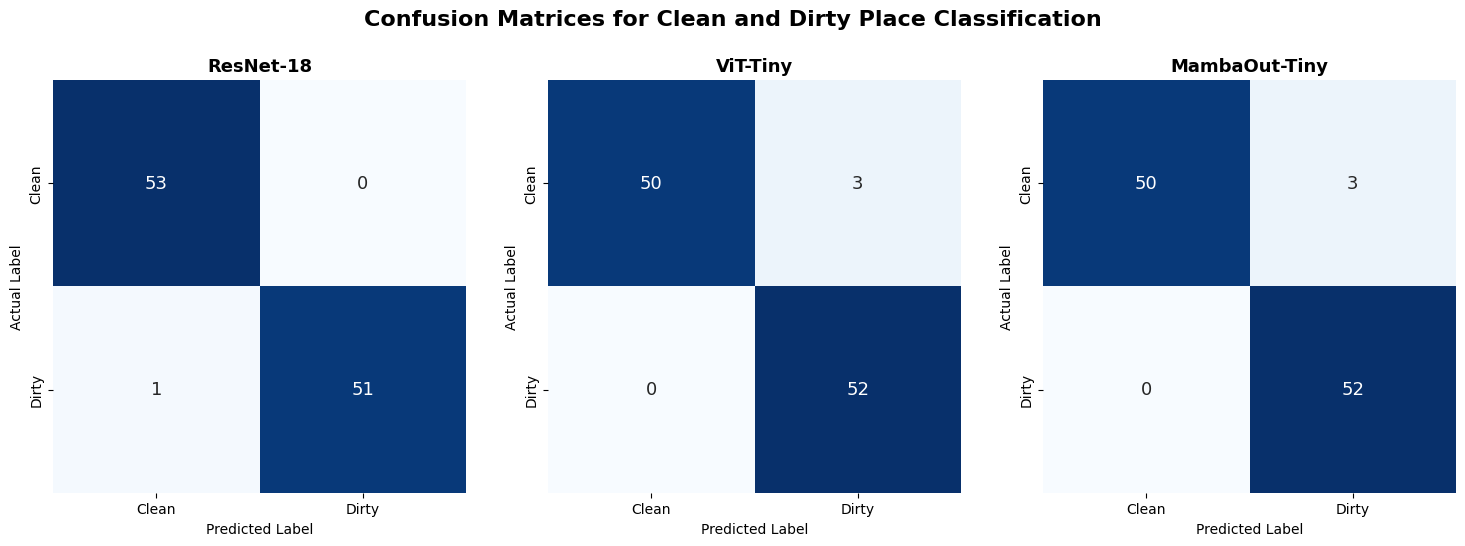

Confusion matrices saved to: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba/outputs/figures/confusion_matrices_comparison.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba"
)
FIGURES_DIR = PROJECT_DIR / "outputs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

model_names = ["ResNet-18", "ViT-Tiny", "MambaOut-Tiny"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, model_name in zip(axes, model_names):
    y_true = test_predictions[model_name]["y_true"]
    y_pred = test_predictions[model_name]["y_pred"]

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        square=True,
        xticklabels=["Clean", "Dirty"],
        yticklabels=["Clean", "Dirty"],
        annot_kws={"size": 13},
        ax=ax
    )

    ax.set_title(model_name, fontsize=13, fontweight="bold")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

fig.suptitle(
    "Confusion Matrices for Clean and Dirty Place Classification",
    fontsize=16,
    fontweight="bold",
    y=1.04
)

plt.tight_layout()

figure_path = FIGURES_DIR / "confusion_matrices_comparison.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

print("Confusion matrices saved to:", figure_path)

#Plot Training and Validation Curves

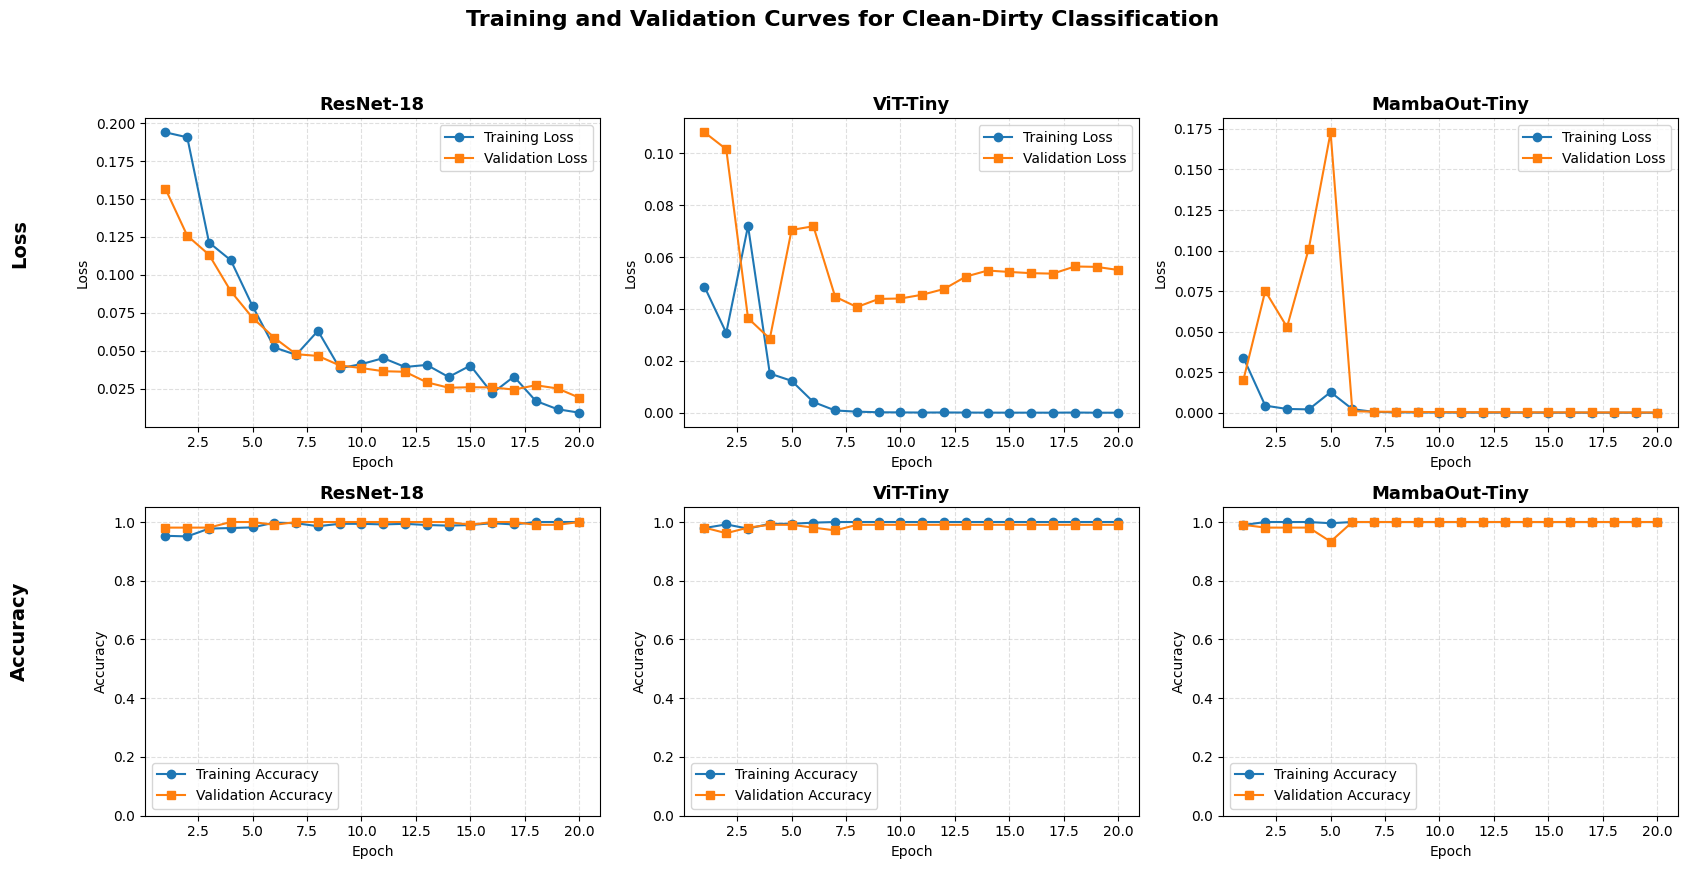

Figure saved successfully!
Saved path: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba/outputs/figures/training_validation_curves.png


In [ ]:

import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

# Project directories
PROJECT_DIR = Path(
    "/content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba"
)
RESULTS_DIR = PROJECT_DIR / "outputs" / "results"
FIGURES_DIR = PROJECT_DIR / "outputs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

model_names = ["ResNet-18", "ViT-Tiny", "MambaOut-Tiny"]

# One figure: 2 rows x 3 columns
fig, axes = plt.subplots(2, 3, figsize=(17, 9))

for col, model_name in enumerate(model_names):

    file_name = (
        model_name.lower().replace("-", "_").replace(" ", "_")
        + "_training_history.csv"
    )
    history_path = RESULTS_DIR / file_name
    history_df = pd.read_csv(history_path)

    epochs = history_df["epoch"]

    # First row: Loss curves
    axes[0, col].plot(
        epochs,
        history_df["train_loss"],
        marker="o",
        label="Training Loss"
    )
    axes[0, col].plot(
        epochs,
        history_df["val_loss"],
        marker="s",
        label="Validation Loss"
    )
    axes[0, col].set_title(model_name, fontsize=13, fontweight="bold")
    axes[0, col].set_xlabel("Epoch")
    axes[0, col].set_ylabel("Loss")
    axes[0, col].legend()
    axes[0, col].grid(True, linestyle="--", alpha=0.4)

    # Second row: Accuracy curves
    axes[1, col].plot(
        epochs,
        history_df["train_accuracy"],
        marker="o",
        label="Training Accuracy"
    )
    axes[1, col].plot(
        epochs,
        history_df["val_accuracy"],
        marker="s",
        label="Validation Accuracy"
    )
    axes[1, col].set_title(model_name, fontsize=13, fontweight="bold")
    axes[1, col].set_xlabel("Epoch")
    axes[1, col].set_ylabel("Accuracy")
    axes[1, col].set_ylim(0, 1.05)
    axes[1, col].legend()
    axes[1, col].grid(True, linestyle="--", alpha=0.4)

# Row labels
fig.text(
    0.01, 0.72, "Loss",
    rotation=90, va="center",
    fontsize=14, fontweight="bold"
)
fig.text(
    0.01, 0.29, "Accuracy",
    rotation=90, va="center",
    fontsize=14, fontweight="bold"
)

fig.suptitle(
    "Training and Validation Curves for Clean-Dirty Classification",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout(rect=[0.04, 0.02, 1, 0.94])

# Save high-resolution figure
figure_path = FIGURES_DIR / "training_validation_curves.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Figure saved successfully!")
print("Saved path:", figure_path)


#Visualize Correct and Incorrect Predictions

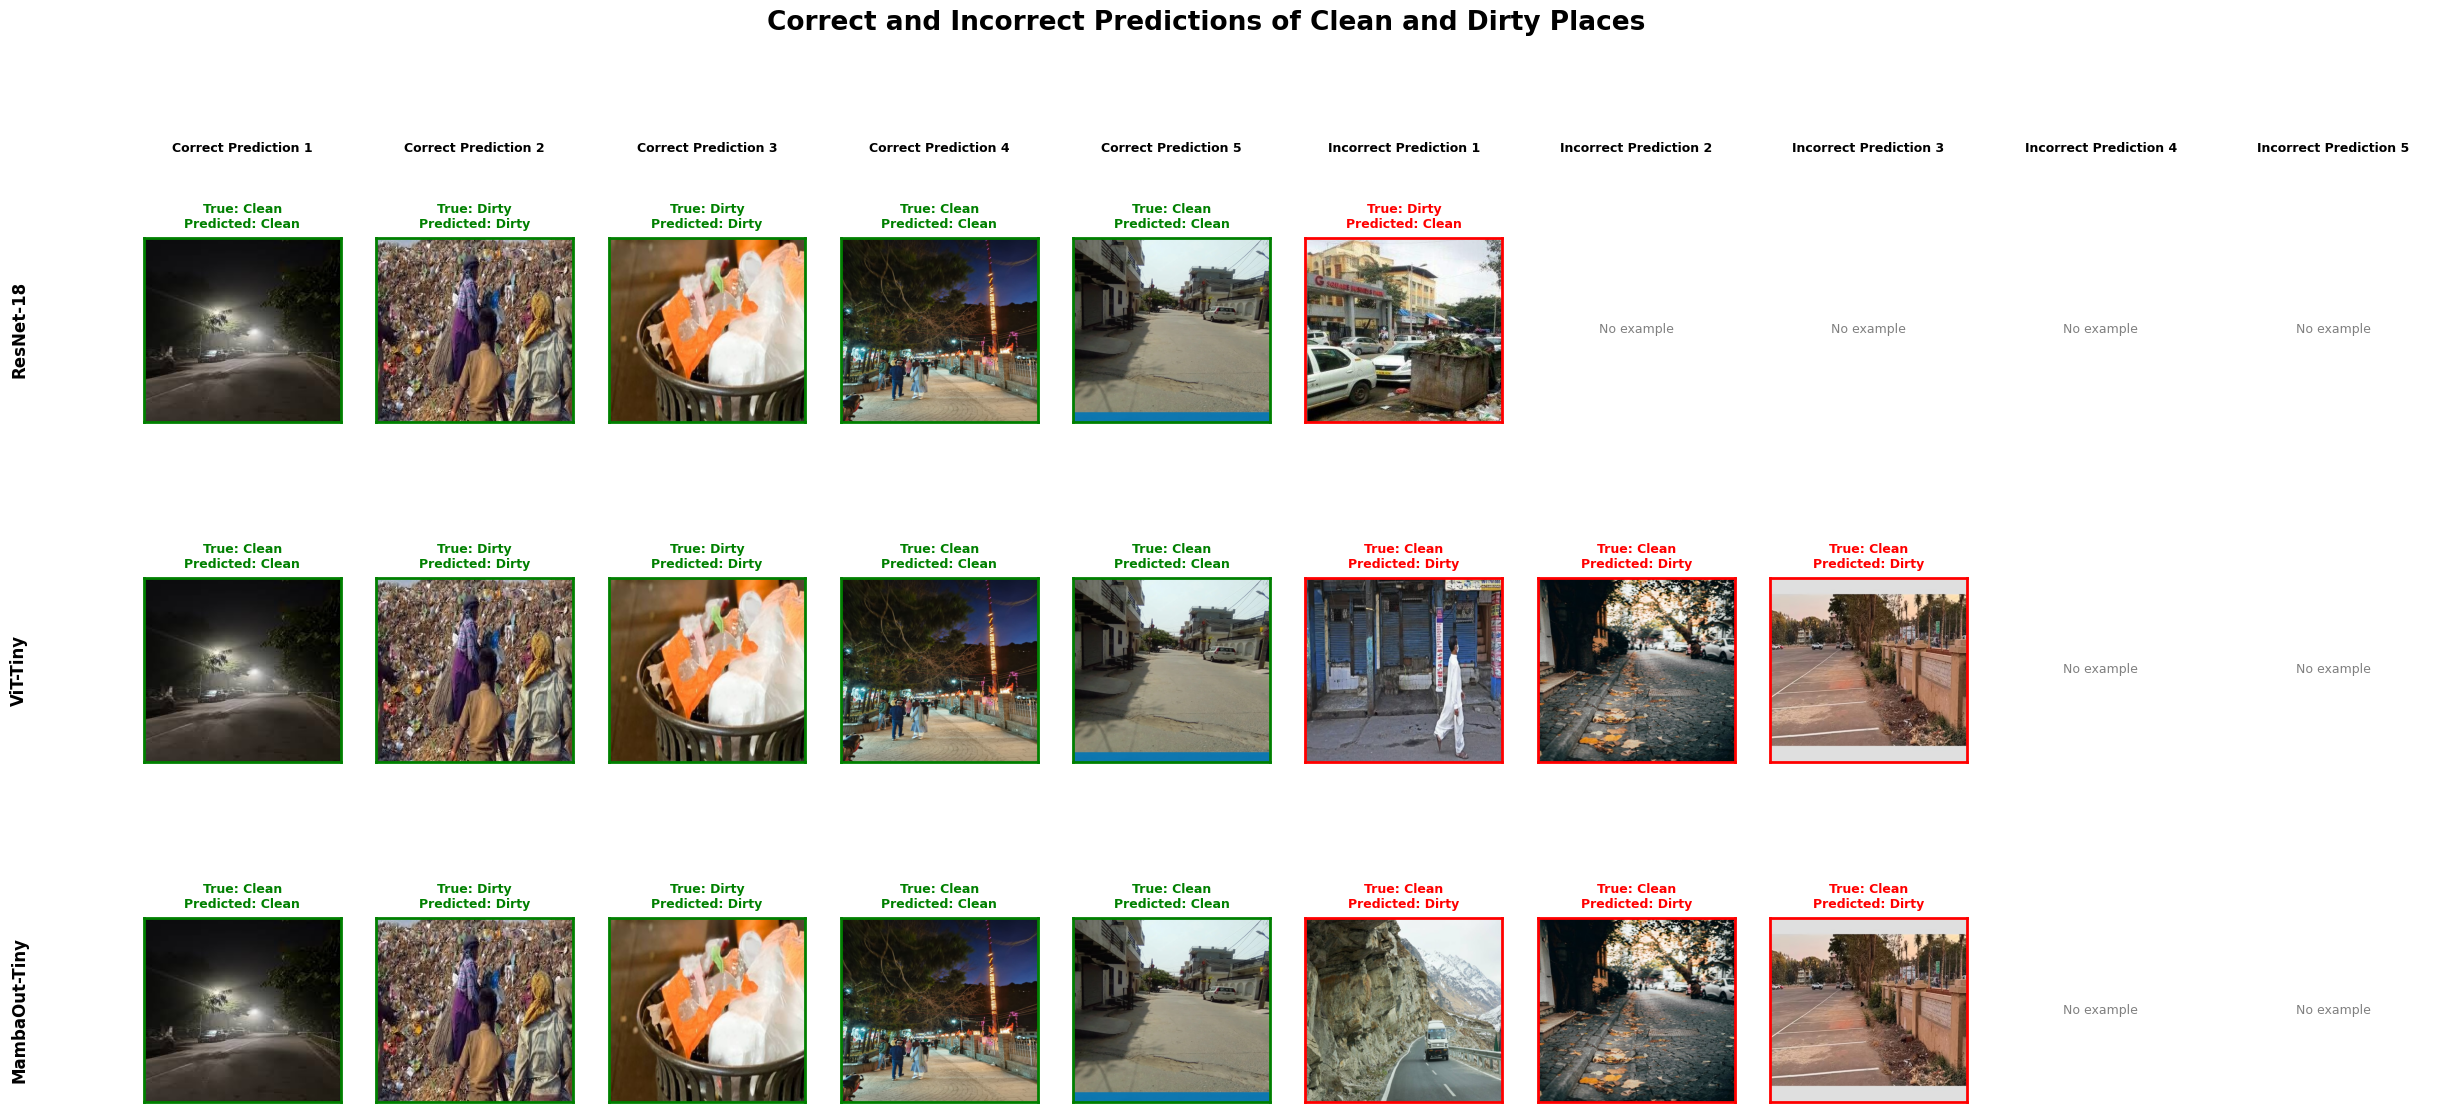

Figure saved successfully to:
/content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba/outputs/figures/correct_incorrect_predictions_all_models.png


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pathlib import Path
from PIL import Image

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba"
)
FIGURES_DIR = PROJECT_DIR / "outputs" / "figures"
RESULTS_DIR = PROJECT_DIR / "outputs" / "results"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

model_names = ["ResNet-18", "ViT-Tiny", "MambaOut-Tiny"]
NUM_CORRECT = 5
NUM_INCORRECT = 5
NUM_COLS = NUM_CORRECT + NUM_INCORRECT

CLASS_NAMES = {0: "Clean", 1: "Dirty"}

if "test_df" not in globals():
    test_df = pd.read_csv(RESULTS_DIR / "test_split.csv")

if "test_predictions" not in globals():
    raise NameError(
        "Run the model evaluation cell first to create test_predictions."
    )

# Fixed figure dimensions and spacing
fig, axes = plt.subplots(
    nrows=3,
    ncols=10,
    figsize=(25, 12),
    gridspec_kw={
        "left": 0.075,
        "right": 0.99,
        "bottom": 0.06,
        "top": 0.78,
        "wspace": 0.18,
        "hspace": 0.85
    }
)

# Main title
fig.suptitle(
    "Correct and Incorrect Predictions of Clean and Dirty Places",
    fontsize=19,
    fontweight="bold",
    y=0.97
)

# Fixed column titles: independent of image size
column_titles = [
    f"Correct Prediction {i}" for i in range(1, 6)
] + [
    f"Incorrect Prediction {i}" for i in range(1, 6)
]

for col_idx, title in enumerate(column_titles):
    pos = axes[0, col_idx].get_position()
    center_x = (pos.x0 + pos.x1) / 2

    fig.text(
        center_x,
        0.855,
        title,
        ha="center",
        va="center",
        fontsize=9,
        fontweight="bold",
        wrap=True
    )

# Plot predictions
for row_idx, model_name in enumerate(model_names):

    prediction_data = test_predictions[model_name]
    y_true = np.asarray(prediction_data["y_true"])
    y_pred = np.asarray(prediction_data["y_pred"])

    correct_indices = np.where(y_true == y_pred)[0][:NUM_CORRECT]
    incorrect_indices = np.where(y_true != y_pred)[0][:NUM_INCORRECT]

    selected_indices = list(correct_indices) + list(incorrect_indices)

    # Model name at the start of each row
    row_pos = axes[row_idx, 0].get_position()
    center_y = (row_pos.y0 + row_pos.y1) / 2

    fig.text(
        0.025,
        center_y,
        model_name,
        ha="center",
        va="center",
        rotation=90,
        fontsize=12,
        fontweight="bold"
    )

    for col_idx, ax in enumerate(axes[row_idx]):
        ax.clear()
        ax.set_xticks([])
        ax.set_yticks([])

        # Keep all image panels the same size and position
        for spine in ax.spines.values():
            spine.set_visible(False)

        if col_idx >= len(selected_indices):
            ax.text(
                0.5, 0.5,
                "No example",
                transform=ax.transAxes,
                ha="center",
                va="center",
                fontsize=9,
                color="gray"
            )
            continue

        pred_idx = selected_indices[col_idx]
        image_path = test_df.iloc[pred_idx]["image_path"]

        with Image.open(image_path) as img:
            image = img.convert("RGB")
            ax.imshow(image, aspect="auto")

        true_label = CLASS_NAMES[int(y_true[pred_idx])]
        predicted_label = CLASS_NAMES[int(y_pred[pred_idx])]
        is_correct = true_label == predicted_label

        # Identical title position for every image
        ax.set_title(
            f"True: {true_label}\nPredicted: {predicted_label}",
            fontsize=9,
            fontweight="bold",
            color="green" if is_correct else "red",
            pad=7,
            loc="center"
        )

        # Colored border
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(2)
            spine.set_edgecolor("green" if is_correct else "red")

# Save without tight_layout or bbox_inches="tight",
# so the fixed title positions remain unchanged.
output_path = FIGURES_DIR / "correct_incorrect_predictions_all_models.png"

fig.savefig(output_path, dpi=300)
plt.show()

print(f"Figure saved successfully to:\n{output_path}")

#Compare Model Size and Inference Speed

In [ ]:

import time
import torch
import timm
import pandas as pd
from pathlib import Path

# Project directories
PROJECT_DIR = Path(
    "/content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba"
)
MODELS_DIR = PROJECT_DIR / "outputs" / "models"
RESULTS_DIR = PROJECT_DIR / "outputs" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

MODEL_CONFIGS = {
    "ResNet-18": "resnet18",
    "ViT-Tiny": "vit_tiny_patch16_224",
    "MambaOut-Tiny": "mambaout_tiny",
}

# Use a fixed batch size for fair timing
BENCHMARK_BATCH_SIZE = 16
WARMUP_ITERATIONS = 10
TIMED_ITERATIONS = 50

benchmark_results = []

for model_name, model_id in MODEL_CONFIGS.items():

    print(f"\nBenchmarking {model_name}...")

    checkpoint_path = MODELS_DIR / (
        model_name.lower().replace("-", "_").replace(" ", "_")
        + "_best.pth"
    )

    if not checkpoint_path.exists():
        print("Checkpoint not found:", checkpoint_path)
        continue

    # Load the saved model
    model = timm.create_model(
        model_id,
        pretrained=False,
        num_classes=2
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )
    model.load_state_dict(checkpoint["model_state_dict"])
    model = model.to(DEVICE)
    model.eval()

    # Parameter counts
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(
        p.numel() for p in model.parameters() if p.requires_grad
    )

    # Checkpoint size in MB
    checkpoint_size_mb = checkpoint_path.stat().st_size / (1024 ** 2)

    # Fixed input batch
    dummy_input = torch.randn(
        BENCHMARK_BATCH_SIZE, 3, 224, 224, device=DEVICE
    )

    # Warm-up
    with torch.inference_mode():
        for _ in range(WARMUP_ITERATIONS):
            _ = model(dummy_input)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    # Measure repeated batch inference
    start_time = time.perf_counter()

    with torch.inference_mode():
        for _ in range(TIMED_ITERATIONS):
            _ = model(dummy_input)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    elapsed_seconds = time.perf_counter() - start_time

    total_images = BENCHMARK_BATCH_SIZE * TIMED_ITERATIONS
    latency_ms = elapsed_seconds * 1000 / total_images
    throughput = total_images / elapsed_seconds

    benchmark_results.append({
        "model": model_name,
        "total_parameters": total_params,
        "trainable_parameters": trainable_params,
        "checkpoint_size_MB": round(checkpoint_size_mb, 2),
        "batch_size": BENCHMARK_BATCH_SIZE,
        "latency_ms_per_image": round(latency_ms, 3),
        "throughput_images_per_second": round(throughput, 2),
        "device": torch.cuda.get_device_name(0)
                  if DEVICE.type == "cuda" else "CPU",
    })

    print(f"Parameters: {total_params:,}")
    print(f"Checkpoint size: {checkpoint_size_mb:.2f} MB")
    print(f"Latency per image: {latency_ms:.3f} ms")
    print(f"Throughput: {throughput:.2f} images/second")

    del model, dummy_input
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# Save comparison table
benchmark_df = pd.DataFrame(benchmark_results)
benchmark_path = RESULTS_DIR / "computational_comparison.csv"
benchmark_df.to_csv(benchmark_path, index=False)

print("\nComputational Comparison:")
display(benchmark_df)

print("Results saved to:", benchmark_path)



Benchmarking ResNet-18...
Parameters: 11,177,538
Checkpoint size: 42.72 MB
Latency per image: 1.036 ms
Throughput: 965.40 images/second

Benchmarking ViT-Tiny...
Parameters: 5,524,802
Checkpoint size: 21.13 MB
Latency per image: 1.141 ms
Throughput: 876.35 images/second

Benchmarking MambaOut-Tiny...
Parameters: 24,244,706
Checkpoint size: 92.55 MB
Latency per image: 4.842 ms
Throughput: 206.52 images/second

Computational Comparison:


,model,total_parameters,trainable_parameters,checkpoint_size_MB,batch_size,latency_ms_per_image,throughput_images_per_second,device
0,ResNet-18,11177538,11177538,42.72,16,1.036,965.40,Tesla T4
1,ViT-Tiny,5524802,5524802,21.13,16,1.141,876.35,Tesla T4
2,MambaOut-Tiny,24244706,24244706,92.55,16,4.842,206.52,Tesla T4


Results saved to: /content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba/outputs/results/computational_comparison.csv


#Final Model Comparison

In [ ]:
import pandas as pd
from pathlib import Path

# Project directories
PROJECT_DIR = Path(
    "/content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba"
)

RESULTS_DIR = PROJECT_DIR / "outputs" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Load test performance results
test_results = pd.read_csv(
    RESULTS_DIR / "test_model_comparison.csv"
)

# Load computational benchmark results
computational_results = pd.read_csv(
    RESULTS_DIR / "computational_comparison.csv"
)

# Check column names
print("Test result columns:")
print(test_results.columns.tolist())

print("\nComputational result columns:")
print(computational_results.columns.tolist())

Test result columns:
['model', 'test_accuracy', 'test_precision', 'test_recall', 'test_f1', 'true_negatives', 'false_positives', 'false_negatives', 'true_positives']

Computational result columns:
['model', 'total_parameters', 'trainable_parameters', 'checkpoint_size_MB', 'batch_size', 'latency_ms_per_image', 'throughput_images_per_second', 'device']


#Create Final Comparison Table

In [ ]:
import pandas as pd
from pathlib import Path

# Project directories
PROJECT_DIR = Path(
    "/content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba"
)

RESULTS_DIR = PROJECT_DIR / "outputs" / "results"

# Load results
test_results = pd.read_csv(
    RESULTS_DIR / "test_model_comparison.csv"
)

computational_results = pd.read_csv(
    RESULTS_DIR / "computational_comparison.csv"
)

# Merge test performance and computational metrics
final_results = pd.merge(
    test_results,
    computational_results,
    on="model",
    how="inner"
)

# Select and order columns
final_results = final_results[
    [
        "model",
        "test_accuracy",
        "test_precision",
        "test_recall",
        "test_f1",
        "total_parameters",
        "trainable_parameters",
        "checkpoint_size_MB",
        "latency_ms_per_image",
        "throughput_images_per_second",
        "batch_size",
        "device"
    ]
]

# Round metric values for readability
final_results["test_accuracy"] = (
    final_results["test_accuracy"] * 100
).round(2)

final_results["test_precision"] = (
    final_results["test_precision"] * 100
).round(2)

final_results["test_recall"] = (
    final_results["test_recall"] * 100
).round(2)

final_results["test_f1"] = (
    final_results["test_f1"] * 100
).round(2)

final_results["checkpoint_size_MB"] = (
    final_results["checkpoint_size_MB"].round(2)
)

final_results["latency_ms_per_image"] = (
    final_results["latency_ms_per_image"].round(3)
)

final_results["throughput_images_per_second"] = (
    final_results["throughput_images_per_second"].round(2)
)

# Rename columns for the report
final_results = final_results.rename(columns={
    "model": "Model",
    "test_accuracy": "Test Accuracy (%)",
    "test_precision": "Precision (%)",
    "test_recall": "Recall (%)",
    "test_f1": "F1-Score (%)",
    "total_parameters": "Total Parameters",
    "trainable_parameters": "Trainable Parameters",
    "checkpoint_size_MB": "Checkpoint Size (MB)",
    "latency_ms_per_image": "Latency (ms/image)",
    "throughput_images_per_second": "Throughput (images/s)",
    "batch_size": "Batch Size",
    "device": "Device"
})

# Save final comparison
output_path = RESULTS_DIR / "final_model_comparison.csv"
final_results.to_csv(output_path, index=False)

# Display results
print("FINAL MODEL COMPARISON")
display(final_results)

print(f"\nResults saved to:\n{output_path}")

FINAL MODEL COMPARISON


,Model,Test Accuracy (%),Precision (%),Recall (%),F1-Score (%),Total Parameters,Trainable Parameters,Checkpoint Size (MB),Latency (ms/image),Throughput (images/s),Batch Size,Device
0,ResNet-18,99.05,100.00,98.08,99.03,11177538,11177538,42.72,1.036,965.40,16,Tesla T4
1,ViT-Tiny,97.14,94.55,100.00,97.20,5524802,5524802,21.13,1.141,876.35,16,Tesla T4
2,MambaOut-Tiny,97.14,94.55,100.00,97.20,24244706,24244706,92.55,4.842,206.52,16,Tesla T4



Results saved to:
/content/drive/MyDrive/Computer_Vision_Assignments/Assignment15_Mamba/outputs/results/final_model_comparison.csv
